# 2. Modelling — predicting used-car prices

**Input:** `vehicles_clean.csv.gz` produced by `01_data_cleaning.ipynb`.

**Target:** `price` (USD). We model `log(price)` because prices are strongly right-skewed; a log makes errors proportional and the distribution closer to symmetric. Results are reported back in dollars.

**Two final model families:**
- **Linear:** Ridge regression (linear model with L2 penalty), with scaled numbers and one-hot categories.
- **Trees:** Histogram Gradient Boosting (an ensemble of decision trees built one after another), with native handling of categories and missing values.

**Evaluation rule:** the test set is split off first and is used only once, at the end, to compare the two families.

## Summary

**Result (held-out test set, 58,229 cars):**

| Model | MAE ($) | RMSE ($) | Median % error | R² (price) |
|---|---|---|---|---|
| Baseline (median) | 11,114 | 14,735 | 54.2% | -0.05 |
| Linear: Ridge | 4,782 | 8,081 | 20.2% | 0.685 |
| **Trees: Gradient Boosting** | **3,237** | **5,982** | **13.3%** | **0.827** |

**Main findings:**
- Both models beat the baseline by a wide margin.
- The tree model is better on every metric. In permutation importance, `age` and `odometer` are the top two features for the tree model.
- The linear model's largest coefficients are for rare, extreme categories (e.g. `datsun`, `corvette`), which shows that Ridge is sensitive to small categories even with regularisation.

**What each section does:**

| Section | What it does | Why |
|---|---|---|
| 1. Imports and loading | Loads the cleaned CSV, sets the random seed | Same data and reproducible results for both models |
| 2. Features and split | Log-transforms price, splits 80/20 | Test set is held back for one final comparison |
| 3. Evaluation helper | Computes MAE, RMSE, median % error and R² | One scoring function keeps models comparable |
| 4. Baseline | Predicts the median price | Any useful model must beat this |
| 5. Ridge regression | Imputes, scales, one-hot encodes, tunes `alpha` by 5-fold CV | Linear family; penalty stops overfitting with many category columns |
| 5a. Linear coefficients | Lists strongest effects on log price | Shows what the linear model learned and how to read it |
| 6. Gradient boosting | Ordinal-encodes categories, tunes 12 random configurations by 3-fold CV, early stopping | Tree family; handles interactions and missing values natively |
| 7. Comparison | Table and bar chart of all models | Single place to choose the final model |
| 8. Predicted vs actual | Scatter plots on log-log axes | Shows where each model errs (cheap vs expensive cars) |
| 9. Permutation importance | Shuffles each feature on 3,000 test cars | Model-agnostic check of which inputs drive predictions |
| 10. Conclusions | Written summary | See the Summary above |

## 1. Imports and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from scipy.stats import loguniform, randint

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

df = pd.read_csv('vehicles_clean.csv.gz', low_memory=False)
print('Rows:', len(df), '| columns:', df.shape[1])
df.head(3)

Rows: 291142 | columns: 17


,price,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,size,type,paint_color,state,lat,long,age
0,6000,missing,other,missing,NaN,missing,NaN,missing,missing,missing,missing,missing,missing,az,NaN,NaN,NaN
1,11900,missing,other,missing,NaN,missing,NaN,missing,missing,missing,missing,missing,missing,ar,NaN,NaN,NaN
2,21000,missing,other,missing,NaN,missing,NaN,missing,missing,missing,missing,missing,missing,fl,NaN,NaN,NaN


**What this does:** loads the cleaned table and sets a fixed random seed so results are reproducible.

**Why:** reading the cleaned file (not the raw one) guarantees both models see identical data.

## 2. Features, target and train/test split

In [2]:
NUM_COLS = ['age', 'odometer', 'cylinders', 'lat', 'long']
CAT_COLS = ['manufacturer', 'model', 'condition', 'fuel', 'title_status',
            'transmission', 'drive', 'size', 'type', 'paint_color', 'state']

X = df[NUM_COLS + CAT_COLS]
y = np.log(df['price'])          # target on log scale
y_price = df['price']            # same target in dollars, for reporting

X_train, X_test, y_train, y_test, yp_train, yp_test = train_test_split(
    X, y, y_price, test_size=0.2, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (232913, 16) | Test: (58229, 16)


**What this does:** separates the inputs (`X`) from the target, takes the log of the price, and splits 80% train / 20% test.

**Why:** the test set is held back so the final score is an honest estimate on unseen cars. Dollar targets are kept too, so we can report errors in plain money.

**Feature choice:** all 16 cleaned features are used: 5 numeric (`age`, `odometer`, `cylinders`, `lat`, `long`) and 11 categorical (including `manufacturer` and `model`, which overlap; the models handle this).

## 3. Evaluation helper

In [3]:
def evaluate(y_log_true, y_log_pred, y_price_true):
    """Scores on both scales. Price-scale numbers are what a user cares about."""
    pred_price = np.exp(y_log_pred)
    return {
        'MAE ($)': mean_absolute_error(y_price_true, pred_price),
        'RMSE ($)': np.sqrt(mean_squared_error(y_price_true, pred_price)),
        'Median abs % error': np.median(np.abs(pred_price - y_price_true) / y_price_true) * 100,
        'R² (price)': r2_score(y_price_true, pred_price),
        'R² (log price)': r2_score(y_log_true, y_log_pred),
    }

results = {}

**What this does:** a single function that computes the same five metrics for every model.

**Why:**
- **MAE / RMSE in $** answer "how far off is a typical prediction, in dollars?"
- **Median % error** is robust to the few very expensive cars.
- **R² on price and on log price** show how much of the variation is explained.

## 4. Baseline: predict the median

In [4]:
baseline = DummyRegressor(strategy='median')
baseline.fit(X_train, y_train)
results['Baseline (median)'] = evaluate(y_test, baseline.predict(X_test), yp_test)
pd.DataFrame(results).T.round(3)

,MAE ($),RMSE ($),Median abs % error,R² (price),R² (log price)
Baseline (median),11113.853,14734.51,54.178,-0.048,-0.028


**What this does:** always predicts the median price of the training set.

**Why:** any real model must beat this. If it does not, it has learned nothing useful.

## 5. Linear family: Ridge regression

In [5]:
num_linear = Pipeline([
    ('impute', SimpleImputer(strategy='median', add_indicator=True)),  # fill gaps, remember them
    ('scale', StandardScaler()),                                       # same units for all numbers
])
cat_linear = OneHotEncoder(handle_unknown='ignore', sparse_output=True)  # 0/1 column per category

linear_pre = ColumnTransformer([
    ('num', num_linear, NUM_COLS),
    ('cat', cat_linear, CAT_COLS),
])

ridge_pipe = Pipeline([
    ('pre', linear_pre),
    ('model', Ridge()),
])

ridge_search = GridSearchCV(
    ridge_pipe,
    param_grid={'model__alpha': [0.001, 0.01, 0.1, 1, 10]},
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
)
ridge_search.fit(X_train, y_train)
print('Best alpha:', ridge_search.best_params_['model__alpha'])
print('CV MAE (log scale):', -ridge_search.best_score_)
linear_model = ridge_search.best_estimator_
results['Linear: Ridge'] = evaluate(y_test, linear_model.predict(X_test), yp_test)
pd.DataFrame(results).T.round(3)

Best alpha: 0.1
CV MAE (log scale): 0.3081584145454273


,MAE ($),RMSE ($),Median abs % error,R² (price),R² (log price)
Baseline (median),11113.853,14734.510,54.178,-0.048,-0.028
Linear: Ridge,4782.216,8080.749,20.185,0.685,0.694


**What this does:**
1. Fills missing numbers with the median, and adds a flag column saying "this was missing".
2. Standardises numbers (mean 0, spread 1) so the penalty treats them equally.
3. One-hot encodes categories. Categories unseen in training are ignored at prediction time.
4. Fits Ridge regression and picks the penalty strength `alpha` by 5-fold cross-validation on the training set only.

**Why Ridge:** plain linear regression can overfit with ~200 one-hot columns. The L2 penalty shrinks coefficients toward zero, which keeps predictions stable. CV uses the training data only, so the test set stays untouched.

### 5a. What the linear model learned

In [6]:
feat_names = (list(linear_model.named_steps['pre'].transformers_[0][2]) +
              ['missing_' + c for c in np.array(NUM_COLS)[
                  linear_model.named_steps['pre'].named_transformers_['num'].named_steps['impute'].indicator_.features_]] +
              list(linear_model.named_steps['pre'].named_transformers_['cat'].get_feature_names_out(CAT_COLS)))
coefs = pd.Series(linear_model.named_steps['model'].coef_, index=feat_names)
top = pd.concat([coefs.nlargest(10), coefs.nsmallest(10)])
top.sort_values().to_frame('coef (log price)').round(3)

,coef (log price)
title_status_parts only,-0.774
condition_salvage,-0.622
manufacturer_mercury,-0.579
manufacturer_saturn,-0.574
model_fiesta,-0.523
manufacturer_fiat,-0.496
condition_fair,-0.477
model_liberty,-0.437
model_focus,-0.435
model_focus se,-0.417


**What this does:** lists the 10 strongest positive and negative coefficients.

**How to read it:** a coefficient of `c` on the log scale means a one-unit change in that feature multiplies the price by about `exp(c)`. Example: `age` negative = each extra year lowers the price. Category columns are compared against the dropped reference category.

## 6. Tree family: Histogram Gradient Boosting

In [7]:
# Trees do not need scaling or one-hot encoding; ordinal codes + a categorical flag are enough.
cat_tree = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan,
                          encoded_missing_value=np.nan)
tree_pre = ColumnTransformer([
    ('cat', cat_tree, CAT_COLS),
    ('num', 'passthrough', NUM_COLS),   # trees handle NaN in numbers natively
])
is_cat = np.array([True] * len(CAT_COLS) + [False] * len(NUM_COLS))

tree_pipe = Pipeline([
    ('pre', tree_pre),
    ('model', HistGradientBoostingRegressor(categorical_features=is_cat,
                                            random_state=RANDOM_STATE,
                                            early_stopping=True)),
])

tree_space = {
    'model__learning_rate': loguniform(0.02, 0.2),
    'model__max_leaf_nodes': randint(31, 256),
    'model__min_samples_leaf': randint(20, 200),
    'model__l2_regularization': loguniform(1e-3, 10),
}
tree_search = RandomizedSearchCV(
    tree_pipe, tree_space, n_iter=12, cv=3,
    scoring='neg_mean_absolute_error', random_state=RANDOM_STATE, n_jobs=-1,
)
tree_search.fit(X_train, y_train)
print('Best params:', {k.replace('model__', ''): v for k, v in tree_search.best_params_.items()})
print('CV MAE (log scale):', -tree_search.best_score_)
tree_model = tree_search.best_estimator_
results['Trees: Gradient Boosting'] = evaluate(y_test, tree_model.predict(X_test), yp_test)
pd.DataFrame(results).T.round(3)

Best params: {'l2_regularization': np.float64(0.12563152773938666), 'learning_rate': np.float64(0.05022164887854354), 'max_leaf_nodes': 250, 'min_samples_leaf': 34}
CV MAE (log scale): 0.2246849860244058


,MAE ($),RMSE ($),Median abs % error,R² (price),R² (log price)
Baseline (median),11113.853,14734.510,54.178,-0.048,-0.028
Linear: Ridge,4782.216,8080.749,20.185,0.685,0.694
Trees: Gradient Boosting,3237.397,5981.552,13.264,0.827,0.826


**What this does:**
1. Encodes categories as integer codes and marks them as categorical, so the trees split on category groups directly.
2. Leaves numbers as they are; missing numbers are handled inside the trees.
3. Randomly tries 12 hyperparameter combinations (learning rate, tree size, minimum leaf size, regularisation), scoring each by 3-fold CV on the training set.
4. Early stopping ends boosting when validation error stops improving.

**Why:** boosting builds many small trees, each correcting the previous one's errors. It captures interactions (e.g. "age matters more for trucks") that a linear model cannot. A random search is cheaper than a full grid and works well for these settings.

## 7. Final comparison on the held-out test set

,MAE ($),RMSE ($),Median abs % error,R² (price),R² (log price)
Baseline (median),11113.853,14734.510,54.178,-0.048,-0.028
Linear: Ridge,4782.216,8080.749,20.185,0.685,0.694
Trees: Gradient Boosting,3237.397,5981.552,13.264,0.827,0.826


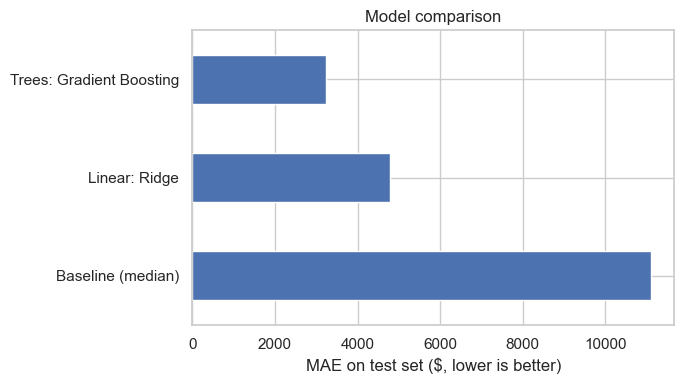

In [8]:
res_df = pd.DataFrame(results).T
display(res_df.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
res_df[['MAE ($)']].plot.barh(ax=ax, legend=False)
ax.set_xlabel('MAE on test set ($, lower is better)')
ax.set_title('Model comparison')
plt.tight_layout(); plt.show()

**What this does:** puts all three models in one table and bar chart.

**Why:** a single table makes the decision clear. MAE in dollars is the most interpretable headline number.

## 8. Predicted vs actual prices (test set)

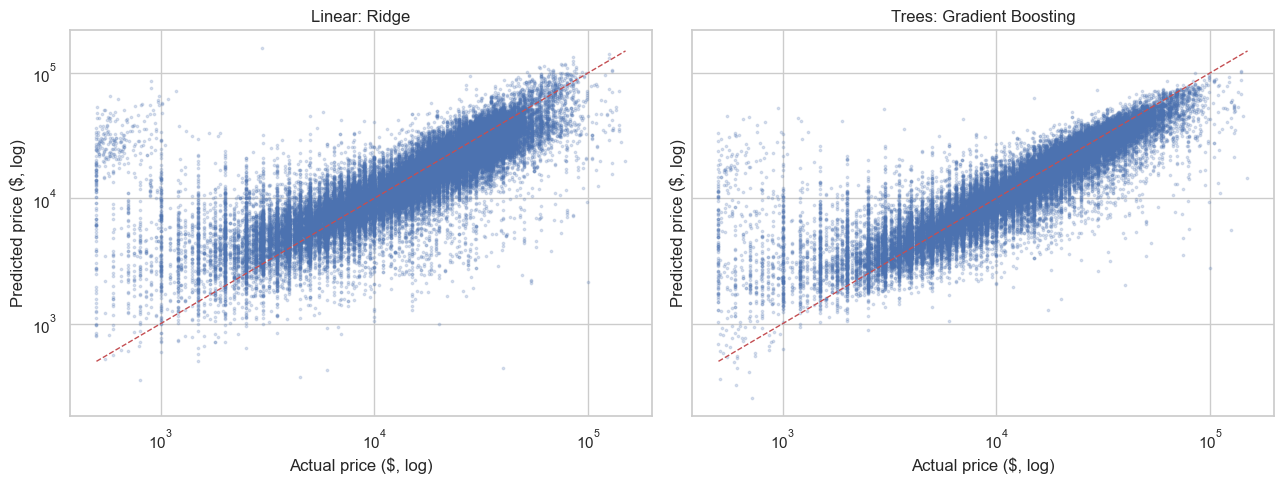

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, [('Linear: Ridge', linear_model), ('Trees: Gradient Boosting', tree_model)]):
    p = np.exp(model.predict(X_test))
    ax.scatter(yp_test, p, s=3, alpha=0.2)
    ax.plot([500, 150000], [500, 150000], 'r--', lw=1)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title(name); ax.set_xlabel('Actual price ($, log)'); ax.set_ylabel('Predicted price ($, log)')
plt.tight_layout(); plt.show()

**What this does:** plots each test car's prediction against its real price. Points on the red line are perfect predictions.

**Why:** a metric hides where the errors are; the plot shows whether one model is systematically off in the cheap or expensive range.

## 9. Which features matter most for the tree model?

In [10]:
sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_test), size=3000, replace=False)
pi = permutation_importance(tree_model, X_test.iloc[sample_idx], y_test.iloc[sample_idx],
                            n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1,
                            scoring='neg_mean_absolute_error')
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.round(4).to_frame('MAE increase when shuffled (log scale)')

,MAE increase when shuffled (log scale)
age,0.3618
odometer,0.1491
manufacturer,0.0773
model,0.0667
cylinders,0.0550
type,0.0430
fuel,0.0378
drive,0.0351
condition,0.0257
state,0.0138


**What this does:** shuffles one feature at a time on 3,000 test cars and measures how much the error grows.

**Why:** a large increase means the model relies on that feature. Permutation importance works for any model, so the same check could be applied to the linear model too.

## 10. All statistical results in one place

In [11]:
# Collects every model's metrics, tuning results and settings into one table.
# The baseline has no tuning; Ridge and gradient boosting report CV scores from training only.
rows = []
for name, r in results.items():
    rows.append({'Model': name, **r})
all_results = pd.DataFrame(rows).set_index('Model')

tuning = pd.DataFrame([
    {'Model': 'Linear: Ridge',
     'Tuned parameters': f"alpha = {ridge_search.best_params_['model__alpha']}",
     'CV folds': 5,
     'CV MAE (log scale)': -ridge_search.best_score_},
    {'Model': 'Trees: Gradient Boosting',
     'Tuned parameters': ', '.join(f"{k.replace('model__', '')} = {float(v):.4g}" if isinstance(v, (float, np.floating)) else f"{k.replace('model__', '')} = {v}"
                                   for k, v in tree_search.best_params_.items()),
     'CV folds': 3,
     'CV MAE (log scale)': -tree_search.best_score_},
]).set_index('Model')

data_info = pd.Series({
    'Total cleaned rows': len(df),
    'Training rows': len(X_train),
    'Test rows': len(X_test),
    'Numeric features': len(NUM_COLS),
    'Categorical features': len(CAT_COLS),
    'Target': 'log(price)',
    'Random seed': RANDOM_STATE,
}).to_frame('value')

print('=== Data ===')
display(data_info)
print('=== Test-set performance (dollars and log scale) ===')
display(all_results.round(3))
print('=== Hyperparameter tuning (training data only) ===')
display(tuning.round(4))
print('=== Permutation importance, tree model (MAE increase on log scale) ===')
display(imp.round(4).to_frame('importance'))
print('=== Linear model: number of non-zero coefficients ===')
print(f"{(linear_model.named_steps['model'].coef_ != 0).sum()} of {len(linear_model.named_steps['model'].coef_)}")

=== Data ===


,value
Total cleaned rows,291142
Training rows,232913
Test rows,58229
Numeric features,5
Categorical features,11
Target,log(price)
Random seed,42


=== Test-set performance (dollars and log scale) ===


,MAE ($),RMSE ($),Median abs % error,R² (price),R² (log price)
Model,,,,,
Baseline (median),11113.853,14734.510,54.178,-0.048,-0.028
Linear: Ridge,4782.216,8080.749,20.185,0.685,0.694
Trees: Gradient Boosting,3237.397,5981.552,13.264,0.827,0.826


=== Hyperparameter tuning (training data only) ===


,Tuned parameters,CV folds,CV MAE (log scale)
Model,,,
Linear: Ridge,alpha = 0.1,5,0.3082
Trees: Gradient Boosting,"l2_regularization = 0.1256, learning_rate = 0....",3,0.2247


=== Permutation importance, tree model (MAE increase on log scale) ===


,importance
age,0.3618
odometer,0.1491
manufacturer,0.0773
model,0.0667
cylinders,0.0550
type,0.0430
fuel,0.0378
drive,0.0351
condition,0.0257
state,0.0138


=== Linear model: number of non-zero coefficients ===
314 of 314


**What this does:** gathers the test metrics of every model, the tuning results (best settings and CV error), the data sizes, the tree model's feature importances and the number of linear coefficients that are non-zero, all in one place.

**Why:** lets you check every statistical result from a single cell, rather than hunting through the notebook.

## 11. Conclusions

**Conclusions**

1. **Trees beat linear.** Gradient boosting reduces the test MAE from $4,782 to $3,237 (about 32%) and raises R² from 0.69 to 0.83.
2. **Remaining error is large in dollars but modest in percent.** A median error of 13% is the current level; the data lacks trim, options and description text, so further gains are likely limited without them.
3. **Limits:** the cleaned data has no description text, VIN or trim level, which are likely strong signals. Cylinders are missing for ~40% of rows, and the tree model still relies on them.
4. **Next steps:** add text features from `description`, try a larger tuning budget, and check whether the log-price predictions need a bias correction when converted back to dollars.